# RoadScan YOLO Benchmarking
Resume the saved benchmark, complete the remaining training stages and evaluate all methods under the same protocol.


## Environment
Install fixed dependencies.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
    'ultralytics==8.4.183', 'sahi==0.11.36', 'pycocotools==2.0.11',
    'numpy', 'pandas', 'matplotlib', 'pyyaml', 'pillow<13', 'scikit-learn'])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 119.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 115.6 MB/s  0:00:00
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.14.0.94
    Uninstalling opencv-python-4.14.0.94:
      Successfully uninstalled opencv-python-4.14.0.94



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


0

## Configuration
Set source paths and shared experiment settings.

In [2]:
from pathlib import Path
import os, json, random, shutil, zipfile, hashlib, gc, platform, contextlib, io, time
from collections import defaultdict
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, yaml
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from IPython.display import display, FileLink

assert version('ultralytics') == '8.4.183', 'Restart the kernel after installing dependencies.'
assert version('sahi') == '0.11.36', 'Restart the kernel after installing dependencies.'

# Paths may remain blank when one matching image dataset is attached.
DATA_SOURCE = ''
BACKUP_SOURCE = ''  # Detect an attached extracted backup or matching ZIP.
REQUIRED_COMPLETED_RUNS = [
    'yolo26n_640', 'yolo26s_640', 'yolo26m_640', 'yolo26l_640',
    'yolo11s_640', 'yolo11m_640', 'yolov8s_640',
]
AUTO_CHECKPOINT_BACKUP = True
MOUNT_GOOGLE_DRIVE = False
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
OUTPUT_BASE = (
    Path('/kaggle/working/RoadScan_YOLO_Benchmarking') if Path('/kaggle/working').is_dir()
    else Path('/content/drive/MyDrive/RoadScan_YOLO_Benchmarking')
    if Path('/content/drive/MyDrive').is_dir()
    else Path.cwd()/'RoadScan_YOLO_Benchmarking'
)
RUN_LABEL = 'benchmark_original_splits'
SESSION = OUTPUT_BASE/RUN_LABEL
SESSION.mkdir(parents=True, exist_ok=True)
LOCAL_BASE = Path('/tmp/roadscan_benchmark_data') if os.name != 'nt' else OUTPUT_BASE/'data_cache'

CLASS_NAMES = ['longitudinal_crack', 'transverse_crack', 'alligator_crack', 'pothole']
CODES = ['D00', 'D10', 'D20', 'D40']
NC = 4
SPLITS = ['train', 'val', 'test', 'saudi_test']
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
EXCLUDE_EMPTY_SAUDI = False
SEED, EPOCHS, FINETUNE_EPOCHS, BATCH, WORKERS = 42, 20, 20, 4, 0
CPU_THREADS, CPU_TIMING_IMAGES, VISUAL_EXAMPLES = 4, 20, 2
CONF_FLOOR, MAX_DET, NMS_IOU = .001, 300, .6
THRESHOLD_GRID = np.round(np.arange(.05, .91, .01), 2)
SAHI_TILES, SAHI_OVERLAP, SAHI_SCREEN_IMAGES = [384, 512], .2, 80

COMPARISON_MODELS = [
    ('yolo26n.pt', 640), ('yolo26s.pt', 640),
    ('yolo26m.pt', 640), ('yolo26l.pt', 640),
    ('yolo11s.pt', 640), ('yolo11m.pt', 640),
    ('yolov8s.pt', 640), ('yolov8m.pt', 640),
    ('yolo26s.pt', 960), ('yolo26m.pt', 960),
]
EXPERIMENTS = [dict(name=f'{Path(weights).stem}_{size}', weights=weights, imgsz=size)
               for weights, size in COMPARISON_MODELS]
AUGMENTATION = dict(fliplr=.5, flipud=0., mosaic=.5, mixup=0.,
    hsv_h=.015, hsv_s=.4, hsv_v=.3, degrees=3., translate=.05,
    scale=.3, shear=0., perspective=0.)
TRAIN_ARGS = dict(epochs=EPOCHS, patience=EPOCHS+1, batch=BATCH, nbs=64,
    optimizer='AdamW', lr0=.001, lrf=.01, weight_decay=.0005,
    cos_lr=True, warmup_epochs=1., close_mosaic=5, amp=True,
    seed=SEED, deterministic=True, cache=False, save=True, save_period=-1,
    plots=True, **AUGMENTATION)
# Fine-tuning starts a new optimizer stage from the baseline's best weight.
FINETUNE_ARGS = {**TRAIN_ARGS, 'epochs':FINETUNE_EPOCHS,
                 'patience':FINETUNE_EPOCHS+1, 'lr0':.0002}
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Output:', SESSION)
print('Base configurations:', len(EXPERIMENTS), '| Device:', DEVICE)
display(pd.DataFrame(EXPERIMENTS))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Output: /kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits
Base configurations: 10 | Device: 0


,name,weights,imgsz
0,yolo26n_640,yolo26n.pt,640
1,yolo26s_640,yolo26s.pt,640
2,yolo26m_640,yolo26m.pt,640
3,yolo26l_640,yolo26l.pt,640
4,yolo11s_640,yolo11s.pt,640
5,yolo11m_640,yolo11m.pt,640
6,yolov8s_640,yolov8s.pt,640
7,yolov8m_640,yolov8m.pt,640
8,yolo26s_960,yolo26s.pt,960
9,yolo26m_960,yolo26m.pt,960


## Data Validation
Verify the original partitions, labels, metadata and file checksums.

In [4]:
DATA_SOURCE = (
    "/kaggle/input/datasets/shathaadelmahrous/"
    "roadscan-benchmark-resume-latest/"
    "RoadScan_Dataset/RoadScan_Dataset/RoadScan_Dataset"
)

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()

def inside(root, relative):
    path = (root / str(relative)).resolve()
    if not path.is_relative_to(root.resolve()):
        raise ValueError(f'Dataset path escapes its root: {relative}')
    return path

def find_root(base):
    base = Path(base)
    roots = {p.parent for p in base.rglob('manifest.jsonl')
             if (p.parent/'images/train').is_dir() and (p.parent/'labels/train').is_dir()}
    if (base/'manifest.jsonl').is_file() and (base/'images/train').is_dir():
        roots.add(base)
    if len(roots) != 1:
        raise ValueError(f'Expected one dataset root with manifest.jsonl, found: {sorted(roots)}')
    return next(iter(roots))

def discover_source(value):
    if value:
        path = Path(value).expanduser().resolve()
        if not path.exists():
            raise FileNotFoundError(f'DATA_SOURCE not found: {path}')
        return path
    bases = [Path('/kaggle/input')] if Path('/kaggle/input').is_dir() else [
        Path('/content/drive/MyDrive'), Path('/content'), Path.cwd()]
    roots = set()
    for base in bases:
        if base.is_dir():
            roots.update(p.parent.resolve() for p in base.rglob('manifest.jsonl')
                         if (p.parent/'images/train').is_dir() and (p.parent/'labels/train').is_dir()
                         and not p.resolve().is_relative_to(LOCAL_BASE.resolve()))
    if len(roots) == 1:
        return next(iter(roots))
    if len(roots) > 1:
        raise ValueError(f'Multiple datasets found; set DATA_SOURCE explicitly: {sorted(roots)}')
    archives = set()
    for base in bases:
        if not base.is_dir():
            continue
        for path in base.rglob('*.zip'):
            if path.resolve().is_relative_to(OUTPUT_BASE.resolve()):
                continue
            with zipfile.ZipFile(path) as archive:
                names = archive.namelist()
                if any(n.endswith('manifest.jsonl') for n in names) and any('/images/train/' in '/' + n for n in names):
                    archives.add(path.resolve())
    if len(archives) != 1:
        raise ValueError(f'Set DATA_SOURCE to the new RoadScan_Dataset folder or ZIP. Candidates: {sorted(archives)}')
    return next(iter(archives))
from pathlib import Path

matches = [
    p for p in Path("/kaggle/input").rglob("dataset_version.json")
    if (p.parent / "images" / "train").is_dir()
    and (p.parent / "labels" / "train").is_dir()
    and (p.parent / "manifest.jsonl").is_file()
]

print("Metadata files found:", [str(p) for p in matches], flush=True)

if len(matches) != 1:
    raise RuntimeError(
        f"Expected exactly one valid dataset; found {len(matches)}."
    )

metadata_path = matches[0]
DATA_ROOT = metadata_path.parent
DATA_SOURCE = DATA_ROOT

print("Using DATA_ROOT:", DATA_ROOT, flush=True)

if not metadata_path.is_file():
    raise FileNotFoundError('The new dataset must include dataset_version.json.')
DATASET_METADATA = json.loads(metadata_path.read_text(encoding='utf-8-sig'))
if DATASET_METADATA.get('class_names') != CLASS_NAMES:
    raise ValueError('Dataset metadata class order differs from D00, D10, D20, D40.')

def list_images(split):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    return sorted(
        p for p in (DATA_ROOT / "images" / split).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )


def label_path(path, split):
    relative = path.relative_to(DATA_ROOT / "images" / split)
    return DATA_ROOT / "labels" / split / relative.with_suffix(".txt")
    
manifest = [json.loads(line) for line in (DATA_ROOT/'manifest.jsonl').read_text(encoding='utf-8-sig').splitlines() if line.strip()]
if len(manifest) != len({row['image'] for row in manifest}):
    raise ValueError('Duplicate image entries in manifest.jsonl.')
manifest_by_image = {row['image']: row for row in manifest}
disk_images = {p.relative_to(DATA_ROOT).as_posix() for split in SPLITS for p in list_images(split)}
all_disk_images = {p.relative_to(DATA_ROOT).as_posix() for p in (DATA_ROOT/'images').rglob('*')
                   if p.is_file() and p.suffix.lower() in IMG_EXT}
if disk_images != all_disk_images or disk_images != set(manifest_by_image):
    raise ValueError('Manifest images and the supplied original split folders do not match.')
for split in SPLITS:
    paths = list_images(split)
    expected_count = DATASET_METADATA.get('splits', {}).get(split, {}).get('images')
    if not paths or expected_count is None or len(paths) != int(expected_count):
        raise ValueError(f'{split}: actual count {len(paths)} differs from dataset metadata {expected_count}.')
    for path in paths:
        relative = path.relative_to(DATA_ROOT).as_posix()
        row = manifest_by_image[relative]
        if row.get('split') != split or inside(DATA_ROOT, row['label']) != label_path(path, split).resolve():
            raise ValueError(f'Manifest image/label/split mismatch: {relative}')
        if split in {'train', 'val', 'test'} and row.get('domain') != 'rdd':
            raise ValueError(f'External data must not enter RDD splits: {relative}')
        if split == 'saudi_test' and row.get('domain') == 'rdd':
            raise ValueError(f'Unexpected RDD image in Saudi external test: {relative}')
if len(manifest) != int(DATASET_METADATA['total_images']):
    raise ValueError('Dataset total differs from dataset_version.json.')

integrity_path = DATA_ROOT/'integrity_sha256.json'
if integrity_path.is_file():
    integrity = json.loads(integrity_path.read_text(encoding='utf-8-sig'))
    required = set(manifest_by_image) | {row['label'] for row in manifest}
    if not required.issubset(integrity):
        raise ValueError('Integrity metadata is missing image or label checksums.')
    for relative in sorted(required):
        path = inside(DATA_ROOT, relative)
        if not path.is_file() or sha256_file(path) != integrity[relative]:
            raise ValueError(f'Dataset file missing or changed: {relative}')
    print('Image and label file checksums verified.')
write_json(SESSION/'dataset_metadata.json', DATASET_METADATA)
print('DATA_ROOT:', DATA_ROOT)
print('Original dataset splits preserved; Saudi data is external test only.')

Metadata files found: ['/kaggle/input/datasets/shathaadelmahrous/roadscan-benchmark-resume-latest/RoadScan_Dataset/RoadScan_Dataset/RoadScan_Dataset/dataset_version.json']
Using DATA_ROOT: /kaggle/input/datasets/shathaadelmahrous/roadscan-benchmark-resume-latest/RoadScan_Dataset/RoadScan_Dataset/RoadScan_Dataset
Image and label file checksums verified.
DATA_ROOT: /kaggle/input/datasets/shathaadelmahrous/roadscan-benchmark-resume-latest/RoadScan_Dataset/RoadScan_Dataset/RoadScan_Dataset
Original dataset splits preserved; Saudi data is external test only.


In [5]:
def read_yolo(path):
    if not path.is_file():
        raise ValueError(f'Missing label: {path}')
    rows = []
    for line_no, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip():
            continue
        try:
            a = np.asarray([float(x) for x in line.split()], dtype=float)
        except ValueError as exc:
            raise ValueError(f'Non-numeric label: {path}:{line_no}') from exc
        if len(a) != 5 or not np.isfinite(a).all():
            raise ValueError(f'Expected 5 finite values: {path}:{line_no}')
        c,x,y,w,h = a
        if c != int(c) or not 0 <= c < NC:
            raise ValueError(f'Invalid class: {path}:{line_no}')
        if not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1):
            raise ValueError(f'Invalid normalized box: {path}:{line_no}')
        if min(x-w/2,y-h/2)<-1e-4 or max(x+w/2,y+h/2)>1.0001:
            raise ValueError(f'Box exceeds image: {path}:{line_no}')
        rows.append(a)
    return np.asarray(rows,dtype=float).reshape(-1,5)

def image_fingerprints(path):
    with Image.open(path) as im:
        im.load()
        if int(im.getexif().get(274,1)) not in (0,1):
            raise ValueError('Normalize EXIF image orientation AND labels before training.')
        rgb=im.convert('RGB')
        w,h=rgb.size
        digest=hashlib.sha256(f'{w}x{h}:'.encode()+rgb.tobytes()).hexdigest()
        small=np.asarray(rgb.convert('L').resize((9,8),Image.Resampling.LANCZOS))
        dhash=sum(int(b)<<i for i,b in enumerate((small[:,1:]>small[:,:-1]).reshape(-1)))
    return w,h,digest,dhash

# Verify the declared class order before interpreting numeric IDs.
declared = yaml.safe_load((DATA_ROOT/'data.yaml').read_text(encoding='utf-8'))['names']
declared = [declared.get(i, declared.get(str(i))) for i in range(NC)] if isinstance(declared,dict) else declared
assert declared == CLASS_NAMES, f'Class mapping mismatch: {declared}'
# Split sizes are verified against dataset_version.json in the preceding cell.
for split in SPLITS:
    expected = {label_path(p,split).resolve() for p in list_images(split)}
    actual = {p.resolve() for p in (DATA_ROOT/'labels'/split).rglob('*.txt')}
    assert expected == actual, f'Missing or orphan labels: {split}'
issues, image_rows, box_rows = [],[],[]
for split in SPLITS:
    for path in list_images(split):
        try:
            labels=read_yolo(label_path(path,split))
            w,h,digest,dhash=image_fingerprints(path)
            entry = manifest_by_image[path.relative_to(DATA_ROOT).as_posix()]
            if 'output_size' in entry and list(entry['output_size']) != [w, h]:
                raise ValueError(f'Manifest image dimensions differ: {path}')
            if 'class_counts' in entry and not np.array_equal(np.bincount(labels[:,0].astype(int),minlength=NC), entry['class_counts']):
                raise ValueError(f'Manifest class counts differ: {path}')
            counts=np.bincount(labels[:,0].astype(int),minlength=NC)
            image_rows.append(dict(split=split,image=str(path),width=w,height=h,
                                   boxes=len(labels),sha256=digest,dhash=dhash,
                                   **{f'{CODES[c]}_boxes':int(counts[c]) for c in range(NC)}))
            for c,x,y,bw,bh in labels:
                box_rows.append(dict(split=split,code=CODES[int(c)],width_px=bw*w,height_px=bh*h))
        except Exception as exc:
            issues.append(dict(split=split,image=str(path),issue=str(exc)))
audit=pd.DataFrame(image_rows)
pd.DataFrame(issues,columns=['split','image','issue']).to_csv(SESSION/'data_issues.csv',index=False)
audit.to_csv(SESSION/'image_audit.csv',index=False)
pd.DataFrame(box_rows).to_csv(SESSION/'box_sizes.csv',index=False)
assert not issues, f'{len(issues)} data errors. Review data_issues.csv and correct the dataset.'

exact_pairs=[]
for _,group in audit.groupby('sha256'):
    group=group.to_dict('records')
    for i,a in enumerate(group):
        for b in group[i+1:]:
            if a['split']!=b['split']:
                exact_pairs.append(dict(split_a=a['split'],image_a=a['image'],split_b=b['split'],image_b=b['image']))
pd.DataFrame(exact_pairs,columns=['split_a','image_a','split_b','image_b']).to_csv(SESSION/'exact_cross_split_duplicates.csv',index=False)
assert not exact_pairs,'Cross-split pixel duplicates found. Correct splits before training.'

# Five disjoint bands: any two hashes with <=4 differing bits share at least one band.
bands, near_pairs = defaultdict(list),[]
records=audit.to_dict('records')
for i,a in enumerate(records):
    value=int(a['dhash'])
    keys=[(k,(value>>lo)&((1<<size)-1)) for k,(lo,size) in enumerate([(0,13),(13,13),(26,13),(39,13),(52,12)])]
    candidates={j for key in keys for j in bands[key]}
    for j in candidates:
        b=records[j]
        if a['split']==b['split'] or a['sha256']==b['sha256']:
            continue
        distance=(value^int(b['dhash'])).bit_count()
        if distance<=4:
            near_pairs.append(dict(split_a=a['split'],image_a=a['image'],split_b=b['split'],image_b=b['image'],distance=distance))
    for key in keys:
        bands[key].append(i)
pd.DataFrame(near_pairs,columns=['split_a','image_a','split_b','image_b','distance']).to_csv(SESSION/'near_duplicate_candidates.csv',index=False)
print('Near-duplicate candidates to REVIEW:',len(near_pairs),'(not removed automatically)')
summary=audit.groupby('split').agg(images=('image','size'),boxes=('boxes','sum'),
                                  empty_labels=('boxes',lambda x:int((x==0).sum())))
summary.to_csv(SESSION/'data_summary.csv')
display(summary)
display(audit.groupby('split')[[f'{c}_boxes' for c in CODES]].sum())
if box_rows:
    display(pd.DataFrame(box_rows).groupby(['split','code'])[['width_px','height_px']].median().round(1))
# Include protocol metadata so changed split definitions cannot resume an old run.
dataset_hasher=hashlib.sha256()
dataset_hasher.update(json.dumps(DATASET_METADATA,sort_keys=True).encode())
dataset_hasher.update((DATA_ROOT/'manifest.jsonl').read_bytes())
for row in records:
    path=Path(row['image'])
    dataset_hasher.update((path.relative_to(DATA_ROOT).as_posix()+row['sha256']).encode())
    dataset_hasher.update(label_path(path,row['split']).read_bytes())
DATASET_FINGERPRINT=dataset_hasher.hexdigest()
print('Dataset fingerprint:',DATASET_FINGERPRINT)

Near-duplicate candidates to REVIEW: 39 (not removed automatically)


,images,boxes,empty_labels
split,,,
saudi_test,100,195,0
test,799,1437,0
train,6404,11662,0
val,797,1433,0


,D00_boxes,D10_boxes,D20_boxes,D40_boxes
split,,,,
saudi_test,103,53,12,27
test,360,360,358,359
train,2972,2883,2916,2891
val,357,357,360,359


width_px  height_px
split      code                     
saudi_test D00      167.0      107.0
           D10      276.0       44.0
           D20      419.0      251.0
           D40      157.5      169.5
test       D00       52.3       89.1
           D10      158.1       30.9
           D20      214.3      161.4
           D40       67.6       40.9
train      D00       52.3       87.5
           D10      160.0       30.0
           D20      210.1      153.6
           D40       65.1       39.1
val        D00       56.5       99.8
           D10      147.2       30.9
           D20      212.8      148.9
           D40       65.8       40.9

Dataset fingerprint: 87a20bcb9a788034ec42b35cb887e798237f2299073bcd347c846cf7013c0274


In [6]:
EVAL_PATHS,excluded={},[]
for split in SPLITS:
    keep=[]
    for path in list_images(split):
        if split=='saudi_test' and EXCLUDE_EMPTY_SAUDI and len(read_yolo(label_path(path,split)))==0:
            excluded.append(dict(split=split,image=str(path),reason='empty label; unconfirmed negative'))
        else:
            keep.append(path)
    assert keep,f'No usable images: {split}'
    EVAL_PATHS[split]=keep
    (SESSION/f'{split}_images.txt').write_text('\n'.join(str(p.resolve()) for p in keep)+'\n',encoding='utf-8')
pd.DataFrame(excluded,columns=['split','image','reason']).to_csv(SESSION/'excluded_images.csv',index=False)
RDD_YAML,SAUDI_YAML=SESSION/'rdd.yaml',SESSION/'saudi.yaml'
dataset_config=dict(path=str(DATA_ROOT.resolve()),
                    train=str((SESSION/'train_images.txt').resolve()),
                    val=str((SESSION/'val_images.txt').resolve()),
                    test=str((SESSION/'test_images.txt').resolve()),
                    names=dict(enumerate(CLASS_NAMES)))
RDD_YAML.write_text(yaml.safe_dump(dataset_config,sort_keys=False),encoding='utf-8')
SAUDI_YAML.write_text(yaml.safe_dump({**dataset_config,'test':str((SESSION/'saudi_test_images.txt').resolve())},sort_keys=False),encoding='utf-8')
print('Saudi evaluation images:',len(EVAL_PATHS['saudi_test']),'Excluded:',len(excluded))

Saudi evaluation images: 100 Excluded: 0


In [7]:
# Apply an explicit training quarantine only when supplied with the new dataset.
quarantine_file = DATA_ROOT/'training_quarantine.csv'
quarantine = pd.DataFrame(columns=['image', 'reason'])
if quarantine_file.is_file():
    quarantine = pd.read_csv(quarantine_file, dtype=str, keep_default_na=False)
    if 'image' not in quarantine.columns:
        raise ValueError('training_quarantine.csv must contain an image column.')
    blocked = set(quarantine['image'])
    available = {p.relative_to(DATA_ROOT).as_posix() for p in EVAL_PATHS['train']}
    if not blocked <= available:
        raise ValueError('Quarantine must reference training images only.')
    EVAL_PATHS['train'] = [p for p in EVAL_PATHS['train'] if p.relative_to(DATA_ROOT).as_posix() not in blocked]
    if not EVAL_PATHS['train']:
        raise ValueError('Quarantine removed all training images.')
    DATASET_FINGERPRINT = hashlib.sha256((DATASET_FINGERPRINT+quarantine_file.read_text(encoding='utf-8')).encode()).hexdigest()
quarantine.to_csv(SESSION/'training_quarantine.csv', index=False)
(SESSION/'train_images.txt').write_text('\n'.join(str(p.resolve()) for p in EVAL_PATHS['train'])+'\n', encoding='utf-8')
effective = []
for split, paths in EVAL_PATHS.items():
    counts = np.zeros(NC, dtype=int)
    for path in paths:
        counts += np.bincount(read_yolo(label_path(path,split))[:,0].astype(int), minlength=NC)
    effective.append(dict(split=split, images=len(paths), **dict(zip(CODES,counts.tolist()))))
pd.DataFrame(effective).to_csv(SESSION/'effective_split_summary.csv', index=False)
display(pd.DataFrame(effective))

,split,images,D00,D10,D20,D40
0,train,6404,2972,2883,2916,2891
1,val,797,357,357,360,359
2,test,799,360,360,358,359
3,saudi_test,100,103,53,12,27


In [8]:
ITEMS = {}
for split, paths in EVAL_PATHS.items():
    items = []
    for path in paths:
        with Image.open(path) as image:
            width, height = image.size
        labels = read_yolo(label_path(path, split))
        truth = labels.copy()
        if len(labels):
            truth[:, 1:3] = (labels[:, 1:3]-labels[:, 3:]/2)*[width, height]
            truth[:, 3:5] = (labels[:, 1:3]+labels[:, 3:]/2)*[width, height]
        items.append(dict(image=str(path), key=path.relative_to(DATA_ROOT).as_posix(),
                          image_sha256=sha256_file(path), truth=truth, width=width, height=height))
    ITEMS[split] = items
print('Original split images:', {s:len(v) for s,v in ITEMS.items()})

Original split images: {'train': 6404, 'val': 797, 'test': 799, 'saudi_test': 100}


## Recovery and Training Control
Restore the compatible backup and verify completed experiments before continuing.


In [9]:
from contextlib import contextmanager
from unittest.mock import patch
from ultralytics.data import augment as yolo_augment

def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

save_json = write_json
file_hash = sha256_file

def copy_verified(source, target):
    source, target = Path(source), Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if source.resolve() == target.resolve():
        return
    temporary = target.with_name(target.name + '.copying')
    shutil.copyfile(source, temporary)
    if file_hash(source) != file_hash(temporary):
        raise IOError(f'Backup verification failed: {source}')
    temporary.replace(target)

BENCHMARK_PROTOCOL = dict(
    dataset_fingerprint=DATASET_FINGERPRINT, classes=CLASS_NAMES,
    experiments=EXPERIMENTS, train_args=TRAIN_ARGS, finetune_args=FINETUNE_ARGS,
    seed=SEED, versions=dict(ultralytics=version('ultralytics'),
                           sahi=version('sahi'), torch=str(torch.__version__)),
    image_size_policy='Original split folders; no held-out-country repartition',
    evaluation=dict(engine='pycocotools', max_det=MAX_DET, floor=CONF_FLOOR,
                    iou=NMS_IOU, confidence_selection='validation macro detection F1'),
)

def restore_backup():
    # Accept an extracted backup or a ZIP attached as a Kaggle input.
    candidates = []
    source = Path(BACKUP_SOURCE).expanduser() if BACKUP_SOURCE else Path('/kaggle/input')
    if BACKUP_SOURCE and not source.exists():
        raise FileNotFoundError(f'Backup source missing: {source}')
    if source.is_file():
        archives = [source]
        protocols = []
    else:
        archives = sorted(source.rglob('*.zip')) if source.is_dir() else []
        protocols = sorted(source.rglob('benchmark_protocol.json')) if source.is_dir() else []
    for path in protocols:
        if json.loads(path.read_text(encoding='utf-8')) == BENCHMARK_PROTOCOL:
            candidates.append(('folder', path.parent, None))
    for archive_path in archives:
        if not zipfile.is_zipfile(archive_path):
            continue
        with zipfile.ZipFile(archive_path) as archive:
            for member in archive.namelist():
                if Path(member).name == 'benchmark_protocol.json':
                    if json.loads(archive.read(member).decode('utf-8-sig')) == BENCHMARK_PROTOCOL:
                        candidates.append(('zip', archive_path, member))
    # Identical duplicate archives represent the same saved backup.
    unique = {}
    for kind, path, member in candidates:
        key = (kind, file_hash(path) if kind == 'zip' else str(path.resolve()), member)
        unique.setdefault(key, (kind, path, member))
    candidates = list(unique.values())
    if len(candidates) > 1:
        raise ValueError('Multiple compatible backups found. Set BACKUP_SOURCE to the latest single ZIP or extracted folder.')
    if not candidates:
        if BACKUP_SOURCE or protocols:
            raise ValueError('No compatible backup: check dataset, training settings and library versions.')
        print('No attached compatible backup found; checking existing local completed runs.')
        return
    kind, source, member = candidates[0]
    if kind == 'zip':
        target = LOCAL_BASE/'benchmark_backups'/file_hash(source)[:16]
        marker = target/'extraction_complete.json'
        if not marker.is_file():
            with zipfile.ZipFile(source) as archive:
                for info in archive.infolist():
                    inside(target, info.filename)
                damaged = archive.testzip()
                if damaged:
                    raise IOError(f'Damaged backup member: {damaged}')
                archive.extractall(target)
            save_json(marker, dict(sha256=file_hash(source)))
        source = (target/member).parent
    training_root = SESSION/'training'
    local_runs = {
        folder.name for folder in training_root.iterdir()
        if folder.is_dir() and any((folder/'weights').glob('*.pt'))
    } if training_root.is_dir() else set()
    for path in source.rglob('*'):
        if not path.is_file():
            continue
        relative = path.relative_to(source)
        if len(relative.parts)>1 and relative.parts[0]=='training' and relative.parts[1] in local_runs:
            continue
        target = SESSION/relative
        if not target.exists():
            copy_verified(path, target)
    print('Benchmark backup restored from:', source)

protocol_path = SESSION/'benchmark_protocol.json'
if protocol_path.is_file() and json.loads(protocol_path.read_text()) != BENCHMARK_PROTOCOL:
    raise RuntimeError('This session belongs to different data/settings. Choose a new RUN_LABEL.')
restore_backup()
save_json(protocol_path, BENCHMARK_PROTOCOL)
save_json(SESSION/'environment.json', dict(
    python=platform.python_version(), torch=str(torch.__version__),
    ultralytics=version('ultralytics'), sahi=version('sahi'),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
))

# Prevent accidental retraining when the recovery dataset is missing.
for name in REQUIRED_COMPLETED_RUNS:
    folder = SESSION/'training'/name
    needed = ['completed.json', 'run_identity.json', 'results.csv', 'weights/best.pt', 'weights/last.pt']
    missing = [item for item in needed if not (folder/item).is_file()]
    if missing:
        raise FileNotFoundError(f'{name}: attach RoadScan_Benchmark_Resume_Latest.zip before training. Missing: {missing}')
    identity = json.loads((folder/'run_identity.json').read_text())
    if identity['protocol_sha256'] != object_hash(BENCHMARK_PROTOCOL):
        raise ValueError(f'{name}: incompatible saved run identity.')
    completed = json.loads((folder/'completed.json').read_text())
    history = pd.read_csv(folder/'results.csv')
    if (len(history) != EPOCHS or int(history['epoch'].max()) != EPOCHS
            or completed['completed_epochs'] != EPOCHS
            or file_hash(folder/'weights/best.pt') != completed['weights_sha256']):
        raise ValueError(f'{name}: completed backup files failed verification.')
    print(f'{name}: verified completed; training will be skipped.')

def checkpoint_backup():
    # Package saved optimizer checkpoints and completed model weights.
    if not AUTO_CHECKPOINT_BACKUP:
        return
    archive = OUTPUT_BASE/'RoadScan_Benchmark_Checkpoints.zip'
    temporary = archive.with_suffix('.partial')
    with zipfile.ZipFile(temporary, 'w', zipfile.ZIP_STORED) as z:
        for path in sorted(SESSION.rglob('*')):
            relative = path.relative_to(SESSION)
            if not path.is_file() or path.name.endswith(('.tmp','.copying')):
                continue
            if relative.parts[0] == 'training' or path == SESSION/'benchmark_protocol.json':
                z.write(path, Path(SESSION.name)/relative)
    with zipfile.ZipFile(temporary) as saved:
        damaged = saved.testzip()
        if damaged:
            raise IOError(f'Backup verification failed: {damaged}')
    temporary.replace(archive)
    print('Checkpoint backup ready:')
    display(FileLink(os.path.relpath(archive, Path.cwd())))

@contextmanager
def explicit_augmentations():
    # Disable optional hidden Albumentations for all runs; the recipe stays explicit.
    class IdentityAugmentation:
        def __init__(self, *args, **kwargs):
            pass
        def __call__(self, labels):
            return labels
    with patch.object(yolo_augment, 'Albumentations', IdentityAugmentation):
        yield

def recorded_epochs(folder):
    path = Path(folder)/'results.csv'
    if not path.is_file():
        return 0
    frame = pd.read_csv(path)
    frame.columns = frame.columns.str.strip()
    if frame.empty or 'epoch' not in frame:
        return 0
    epochs = pd.to_numeric(frame['epoch'], errors='raise').astype(int)
    if epochs.duplicated().any():
        raise ValueError(f'Duplicate training history rows: {path}')
    return int(epochs.max())

def train_model(spec, parent=None):
    folder = SESSION/'training'/spec['name']
    folder.mkdir(parents=True, exist_ok=True)
    args = FINETUNE_ARGS if parent is not None else TRAIN_ARGS
    target_epochs = int(args['epochs'])
    identity = dict(protocol_sha256=object_hash(BENCHMARK_PROTOCOL), specification=spec,
                    parent_sha256=file_hash(parent['weights']) if parent else None,
                    stage_epochs=target_epochs)
    identity_path = folder/'run_identity.json'
    best = folder/'weights/best.pt'
    last = folder/'weights/last.pt'
    marker = folder/'completed.json'
    if identity_path.is_file():
        if json.loads(identity_path.read_text()) != identity:
            raise RuntimeError(f'{spec["name"]}: saved identity does not match.')
    elif best.exists() or last.exists():
        raise RuntimeError(f'{spec["name"]}: existing weights have no run identity.')
    save_json(identity_path, identity)
    completed = recorded_epochs(folder)
    if completed > target_epochs:
        raise RuntimeError('Saved training exceeds the requested stage budget.')

    if marker.is_file():
        saved = json.loads(marker.read_text())
        if (not best.is_file() or saved['weights_sha256'] != file_hash(best)
                or completed != target_epochs):
            raise RuntimeError(f'{spec["name"]}: completed-run files are inconsistent.')
    elif completed != target_epochs or not best.is_file():
        if not torch.cuda.is_available():
            raise RuntimeError('Select a GPU runtime before training.')
        resumed = last.is_file()
        initial = str(last) if resumed else str(parent['weights'] if parent else spec['weights'])
        model = YOLO(initial)
        if model.task != 'detect' or not model.ckpt:
            raise ValueError('A pretrained detection checkpoint is required.')
        if resumed and (int(model.ckpt.get('epoch', -1)) < 0 or model.ckpt.get('optimizer') is None):
            raise RuntimeError('Partial checkpoint has no resumable optimizer state; restore a valid last.pt.')

        def progress(trainer):
            save_json(folder/'training_progress.json', dict(
                completed_epochs=int(trainer.epoch)+1, stage_epochs=target_epochs,
                batch_size=int(trainer.batch_size), accumulation=int(trainer.accumulate),
                optimizer=type(trainer.optimizer).__name__,
                learning_rates=[float(g['lr']) for g in trainer.optimizer.param_groups],
            ))
            # Refresh the backup after each saved epoch.
            checkpoint_backup()
        model.add_callback('on_fit_epoch_end', progress)
        try:
            with explicit_augmentations():
                if resumed:
                    print(spec['name'], 'resuming saved training')
                    model.train(resume=True, device=DEVICE, workers=WORKERS)
                else:
                    save_json(folder/'initialization.json', dict(
                        weights=initial, pretrained_checkpoint_loaded=True,
                        parent_sha256=identity['parent_sha256'],
                    ))
                    model.train(data=str(RDD_YAML), imgsz=spec['imgsz'], device=DEVICE,
                                workers=WORKERS, project=str(folder.parent), name=folder.name,
                                exist_ok=True, **args)
        finally:
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    completed = recorded_epochs(folder)
    if completed != target_epochs or not best.is_file():
        raise RuntimeError(f'{spec["name"]}: training completion is not confirmed.')
    digest = file_hash(best)
    save_json(marker, dict(completed_epochs=completed, weights='weights/best.pt',
                           weights_sha256=digest, selection='Ultralytics validation-selected best'))
    result = dict(name=spec['name'], imgsz=spec['imgsz'], weights=best, hash=digest,
                  folder=folder, stage_epochs=completed, parent=parent['name'] if parent else None)
    print(spec['name'], ': completed', completed, 'stage epochs')
    if spec['name'] not in REQUIRED_COMPLETED_RUNS:
        checkpoint_backup()
    return result

def show_training_history(run):
    frame = pd.read_csv(run['folder']/'results.csv')
    frame.columns = frame.columns.str.strip()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for column in frame:
        if column.startswith('train/') and 'loss' in column:
            axes[0].plot(frame['epoch'], frame[column], label=column)
        elif column.startswith('val/') and 'loss' in column:
            axes[1].plot(frame['epoch'], frame[column], label=column)
        elif column.startswith('metrics/mAP'):
            axes[2].plot(frame['epoch'], frame[column], label=column)
    for ax, title in zip(axes, ['Training losses', 'Validation losses', 'Native validation AP']):
        ax.set(title=title, xlabel='Epoch')
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
    fig.suptitle(run['name'])
    fig.tight_layout()
    fig.savefig(run['folder']/'training_curves.png', dpi=160)
    plt.show()
    plt.close(fig)

Benchmark backup restored from: /kaggle/input/datasets/shathaadelmahrous/roadscan-benchmark-resume-latest/RoadScan_Benchmark_Resume_Latest/benchmark_original_splits
yolo26n_640: verified completed; training will be skipped.
yolo26s_640: verified completed; training will be skipped.
yolo26m_640: verified completed; training will be skipped.
yolo26l_640: verified completed; training will be skipped.
yolo11s_640: verified completed; training will be skipped.
yolo11m_640: verified completed; training will be skipped.
yolov8s_640: verified completed; training will be skipped.


## Shared Evaluation
Use the same COCO evaluator for standard and sliced predictions. Choose operating confidence on validation only.

In [10]:
def clean_predictions(pred,width,height,max_det=MAX_DET):
    pred=np.asarray(pred,dtype=float).reshape(-1,6).copy()
    if not np.isfinite(pred).all():raise ValueError('Non-finite predictions')
    if len(pred):
        if not ((pred[:,5]==pred[:,5].astype(int))&(pred[:,5]>=0)&(pred[:,5]<NC)).all():raise ValueError('Unexpected class IDs')
        if not ((pred[:,4]>=0)&(pred[:,4]<=1)).all():raise ValueError('Invalid confidence')
        pred[:,[0,2]]=np.clip(pred[:,[0,2]],0,width);pred[:,[1,3]]=np.clip(pred[:,[1,3]],0,height)
        pred=pred[(pred[:,2]>pred[:,0])&(pred[:,3]>pred[:,1])]
    return pred[np.argsort(-pred[:,4],kind='stable')[:max_det]]

def box_iou(a,b):
    a=np.asarray(a).reshape(-1,4);b=np.asarray(b).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]);hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1);bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def class_matches(truth,pred):
    used=set();flags=np.zeros(len(pred),bool);overlap=box_iou(pred[:,:4],truth[:,1:])
    for i in np.argsort(-pred[:,4],kind='stable'):
        candidates=[j for j in range(len(truth)) if j not in used and truth[j,0]==pred[i,5] and overlap[i,j]>=.5]
        if candidates:
            j=max(candidates,key=lambda j:overlap[i,j]);used.add(j);flags[i]=True
    return flags

def operating(rows,threshold):
    tp=np.zeros(NC,int);fp=np.zeros(NC,int);support=np.zeros(NC,int)
    for r in rows:
        p=r['pred'][r['pred'][:,4]>=threshold];flags=class_matches(r['truth'],p)
        support+=np.bincount(r['truth'][:,0].astype(int),minlength=NC)
        tp+=np.bincount(p[flags,5].astype(int),minlength=NC)
        fp+=np.bincount(p[~flags,5].astype(int),minlength=NC)
    precision=tp/np.maximum(tp+fp,1);recall=tp/np.maximum(support,1)
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    return dict(P=precision,R=recall,F1=f1,TP=tp,FP=fp,FN=support-tp,support=support)

def detection_ap(rows):
    images=[];annotations=[];detections=[];support=np.zeros(NC,int)
    for i,r in enumerate(rows,1):
        images.append(dict(id=i,width=r['width'],height=r['height']))
        for c,x1,y1,x2,y2 in r['truth']:
            support[int(c)]+=1
            annotations.append(dict(id=len(annotations)+1,image_id=i,category_id=int(c),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],area=float((x2-x1)*(y2-y1)),iscrowd=0))
        for x1,y1,x2,y2,score,c in r['pred']:
            detections.append(dict(image_id=i,category_id=int(c),score=float(score),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)]))
    ap=np.full((NC,10),np.nan)
    if not detections:
        ap[support>0]=0;return ap
    with contextlib.redirect_stdout(io.StringIO()):
        gt=COCO();gt.dataset=dict(info={},images=images,annotations=annotations,categories=[dict(id=i,name=n) for i,n in enumerate(CLASS_NAMES)])
        gt.createIndex();dt=gt.loadRes(detections);ev=COCOeval(gt,dt,'bbox')
        ev.params.catIds=list(range(NC));ev.params.maxDets=[1,10,MAX_DET]
        ev.evaluate();ev.accumulate()
    p=ev.eval['precision'][:,:,:,0,-1]
    for c in range(NC):
        for j in range(10):
            values=p[j,:,c];values=values[values>=0]
            if len(values):ap[c,j]=float(values.mean())
    return ap

def image_targets_scores(rows):
    targets=np.zeros((len(rows),NC),int);scores=np.zeros((len(rows),NC))
    for i,r in enumerate(rows):
        targets[i,r['truth'][:,0].astype(int)]=1
        for c in range(NC):
            values=r['pred'][r['pred'][:,5]==c,4]
            if len(values):scores[i,c]=values.max()
    return targets,scores

def confusion(rows,threshold):
    matrix=np.zeros((NC+1,NC+1),int)
    for r in rows:
        truth=r['truth'];p=r['pred'][r['pred'][:,4]>=threshold]
        overlaps=box_iou(p[:,:4],truth[:,1:]);used=set()
        for i in np.argsort(-p[:,4],kind='stable'):
            candidates=[j for j in range(len(truth)) if j not in used and overlaps[i,j]>=.5]
            if candidates:
                j=max(candidates,key=lambda j:overlaps[i,j]);used.add(j);matrix[int(truth[j,0]),int(p[i,5])]+=1
            else:matrix[NC,int(p[i,5])]+=1
        for j in range(len(truth)):
            if j not in used:matrix[int(truth[j,0]),NC]+=1
    return matrix

In [11]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

def method_for(run, tile=None):
    method = dict(run)
    method['tile'] = tile
    method['method'] = run['name'] if tile is None else f"{run['name']}_sahi_{tile}"
    return method

class Predictor:
    def __init__(self, method, device=DEVICE):
        self.method, self.device = method, device
        if method['tile'] is None:
            self.model = YOLO(str(method['weights']))
        else:
            device_name = f'cuda:{device}' if isinstance(device, int) else str(device)
            self.model = AutoDetectionModel.from_pretrained(
                model_type='ultralytics', model_path=str(method['weights']),
                device=device_name, confidence_threshold=CONF_FLOOR,
                image_size=method['imgsz'],
            )
            self.model.model.overrides.update(iou=NMS_IOU, max_det=MAX_DET, augment=False)
        names = self.model.names if method['tile'] is None else self.model.model.names
        if [names[i] for i in range(NC)] != CLASS_NAMES:
            raise ValueError('Checkpoint class names or order do not match the dataset.')

    def predict(self, path):
        # Return full-image coordinates for both standard and tiled inference.
        with Image.open(path) as image:
            rgb = image.convert('RGB')
        width, height = rgb.size
        if self.method['tile'] is None:
            result = self.model.predict(
                rgb, device=self.device, imgsz=self.method['imgsz'], conf=CONF_FLOOR,
                iou=NMS_IOU, max_det=MAX_DET, augment=False, verbose=False,
            )[0]
            predictions = result.boxes.data.cpu().numpy()[:, :6]
        else:
            tile = int(self.method['tile'])
            result = get_sliced_prediction(
                np.asarray(rgb), self.model, slice_height=tile, slice_width=tile,
                overlap_height_ratio=SAHI_OVERLAP, overlap_width_ratio=SAHI_OVERLAP,
                perform_standard_pred=True, postprocess_type='NMS',
                postprocess_match_metric='IOU', postprocess_match_threshold=NMS_IOU,
                postprocess_class_agnostic=False, auto_slice_resolution=False, verbose=0,
            )
            predictions = np.asarray([
                [*p.bbox.to_xyxy(), p.score.value, p.category.id]
                for p in result.object_prediction_list
            ], dtype=float).reshape(-1, 6)
        return clean_predictions(predictions, width, height)

    def close(self):
        del self.model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

def inference_protocol(method, device):
    return dict(dataset=DATASET_FINGERPRINT, weights=method['hash'], imgsz=method['imgsz'],
                tile=method['tile'], overlap=SAHI_OVERLAP, full_image_pass=True,
                merge='class-aware NMS/IOU' if method['tile'] else 'native detector output',
                confidence_floor=CONF_FLOOR, max_det=MAX_DET, nms_iou=NMS_IOU,
                device=str(device), augment=False,
                versions=dict(ultralytics=version('ultralytics'), sahi=version('sahi'),
                              torch=str(torch.__version__)))

def collect_predictions(method, split, subset=None):
    items = ITEMS[split] if subset is None else subset
    protocol = inference_protocol(method, DEVICE)
    cache = SESSION/'prediction_cache'/object_hash(protocol)[:24]
    cache.mkdir(parents=True, exist_ok=True)
    predictor, rows = None, []
    try:
        for i, record in enumerate(items):
            key = object_hash([record['image_sha256'], record['width'], record['height']])
            path = cache/(key+'.json')
            if not path.is_file():
                if predictor is None:
                    predictor = Predictor(method)
                save_json(path, predictor.predict(record['image']).tolist())
            pred = clean_predictions(json.loads(path.read_text()), record['width'], record['height'])
            rows.append(dict(record, pred=pred))
            if (i+1) % 200 == 0 or i+1 == len(items):
                print(method['method'], split, i+1, '/', len(items))
    finally:
        if predictor is not None:
            predictor.close()
    return rows

def confidence_selection(rows):
    grid = THRESHOLD_GRID
    points = [operating(rows, float(t)) for t in grid]
    scores = np.array([point['F1'].mean() for point in points])
    index = int(np.argmax(scores))
    curve = pd.DataFrame(dict(threshold=grid, macro_F1=scores,
        **{f'F1_{code}': [point['F1'][i] for point in points] for i, code in enumerate(CODES)}))
    return float(grid[index]), curve

def image_presence_metrics(rows, threshold):
    target, scores = image_targets_scores(rows)
    pred = scores >= threshold
    precision, recall, f1, _ = precision_recall_fscore_support(
        target, pred, average='macro', zero_division=0)
    ap = [average_precision_score(target[:, c], scores[:, c])
          for c in range(NC) if target[:, c].sum()]
    return dict(image_macro_AP=float(np.mean(ap)), image_macro_precision=float(precision),
                image_macro_recall=float(recall), image_macro_F1=float(f1),
                image_exact_match=float(np.mean(np.all(target == pred, axis=1))))

def score_rows(method, split, rows, threshold):
    ap = detection_ap(rows)
    point = operating(rows, threshold)
    folder = SESSION/'evaluation'/method['method']
    folder.mkdir(parents=True, exist_ok=True)
    per_class = pd.DataFrame(dict(code=CODES, class_name=CLASS_NAMES,
        AP50=ap[:, 0], AP50_95=np.nanmean(ap, axis=1), **point))
    per_class.to_csv(folder/f'{split}_per_class.csv', index=False)
    summary = dict(method=method['method'], base_run=method['name'], split=split,
        images=len(rows), input_resolution=method['imgsz'], tile=method['tile'],
        stage_epochs=method['stage_epochs'], parent_run=method['parent'],
        threshold=threshold, mAP50=float(np.nanmean(ap[:, 0])),
        mAP50_95=float(np.nanmean(ap)), macro_precision=float(point['P'].mean()),
        macro_recall=float(point['R'].mean()), macro_F1=float(point['F1'].mean()),
        weights_sha256=method['hash'], **image_presence_metrics(rows, threshold))
    save_json(folder/f'{split}_summary.json', summary)
    return summary

def validate_method(method):
    folder = SESSION/'evaluation'/method['method']
    rows = collect_predictions(method, 'val')
    threshold, curve = confidence_selection(rows)
    summary = score_rows(method, 'val', rows, threshold)
    curve.to_csv(folder/'validation_F1_vs_confidence.csv', index=False)
    save_json(folder/'frozen_selection.json', dict(
        method=method['method'], weights_sha256=method['hash'],
        dataset_fingerprint=DATASET_FINGERPRINT, threshold=threshold,
        selected_on='RDD validation only', objective='macro detection F1 at IoU 0.5',
        protocol_sha256=object_hash(inference_protocol(method, DEVICE)),
    ))
    return summary

def visual_evaluation(method, split, rows, threshold):
    folder = SESSION/'evaluation'/method['method']
    matrix = confusion(rows, threshold)
    labels = CODES+['background']
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(folder/f'{split}_confusion.csv')
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(matrix, cmap='Blues')
    for (y, x), value in np.ndenumerate(matrix):
        ax.text(x, y, str(value), ha='center', va='center',
                color='white' if value > matrix.max()/2 else 'black')
    ax.set(xticks=range(NC+1), yticks=range(NC+1), xticklabels=labels,
           yticklabels=labels, xlabel='Prediction', ylabel='Annotation',
           title=f"{method['method']} / {split}")
    ax.tick_params(axis='x', rotation=35)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(folder/f'{split}_confusion.png', dpi=160)
    plt.show()
    plt.close(fig)
    # Fixed first examples avoid selecting only successful predictions.
    for index, record in enumerate(rows[:VISUAL_EXAMPLES]):
        with Image.open(record['image']) as image:
            rgb = np.asarray(image.convert('RGB'))
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        for ax in axes:
            ax.imshow(rgb)
            ax.axis('off')
        for c, x1, y1, x2, y2 in record['truth']:
            axes[0].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='lime'))
            axes[0].text(x1, y1, CODES[int(c)], color='black', backgroundcolor='lime', fontsize=7)
        for x1, y1, x2, y2, confidence, c in record['pred'][record['pred'][:, 4] >= threshold]:
            axes[1].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='cyan'))
            axes[1].text(x1, y1, f'{CODES[int(c)]} {confidence:.2f}', color='black', backgroundcolor='cyan', fontsize=7)
        axes[0].set_title('Annotations')
        axes[1].set_title('Predictions at frozen threshold')
        fig.tight_layout()
        fig.savefig(folder/f'{split}_example_{index+1}.png', dpi=150)
        plt.show()
        plt.close(fig)

## YOLO Configuration Comparison
Train the architecture and resolution configurations with the same recipe.

yolo26n_640 : completed 20 stage epochs


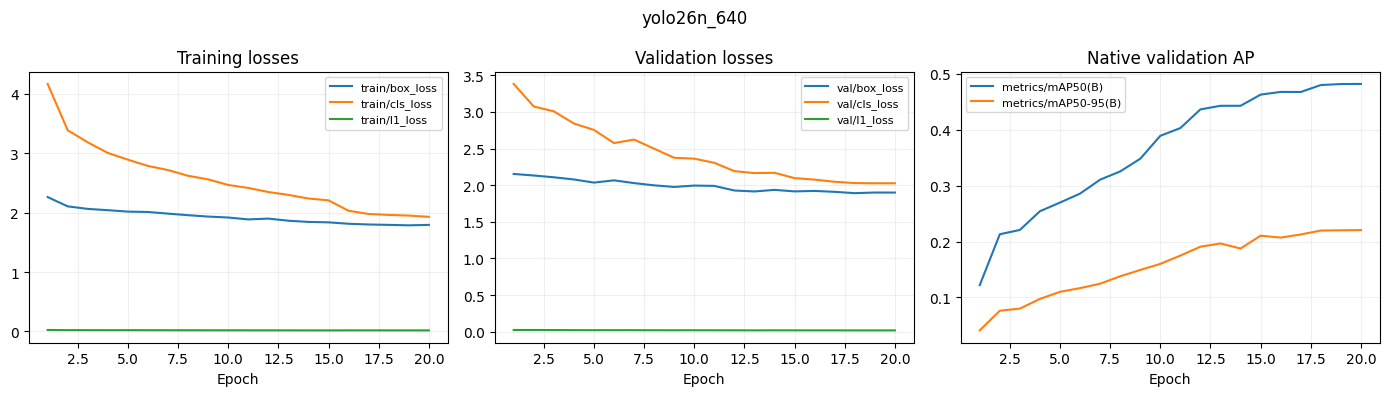

yolo26s_640 : completed 20 stage epochs


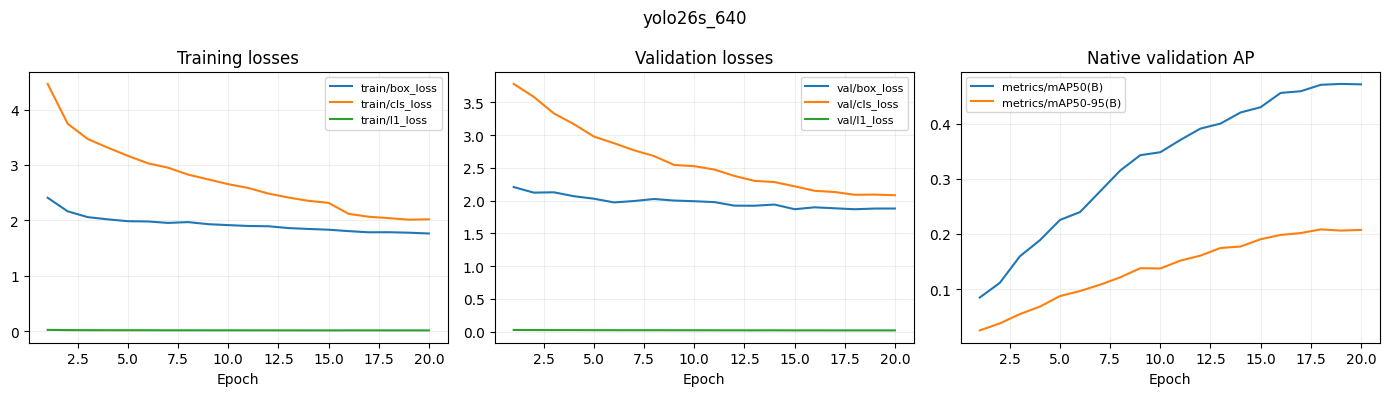

yolo26m_640 : completed 20 stage epochs


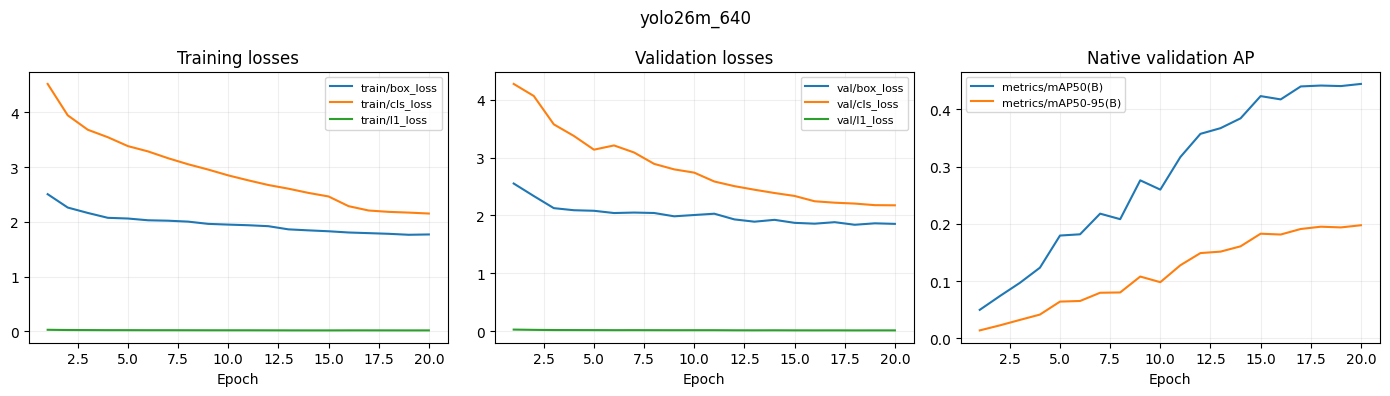

yolo26l_640 : completed 20 stage epochs


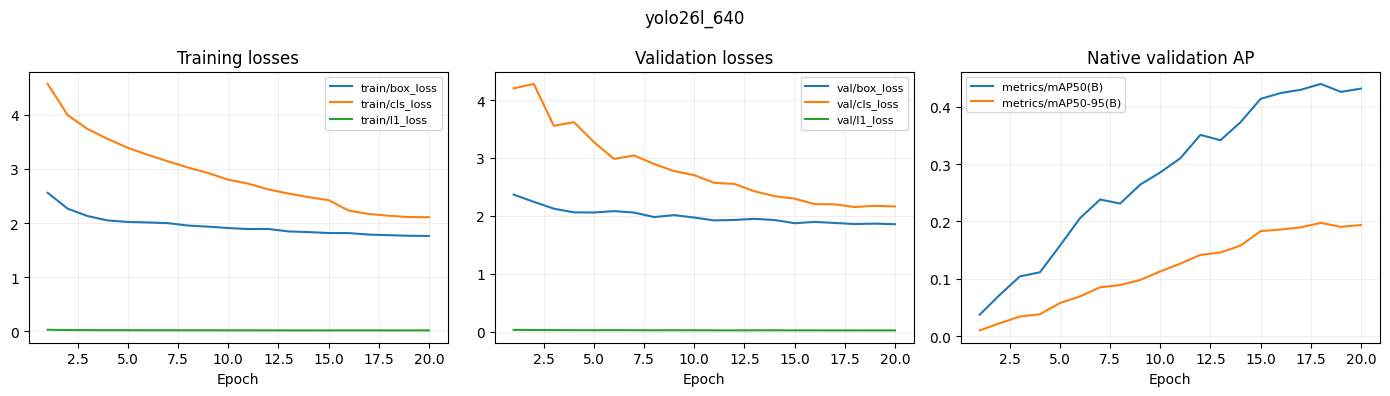

yolo11s_640 : completed 20 stage epochs


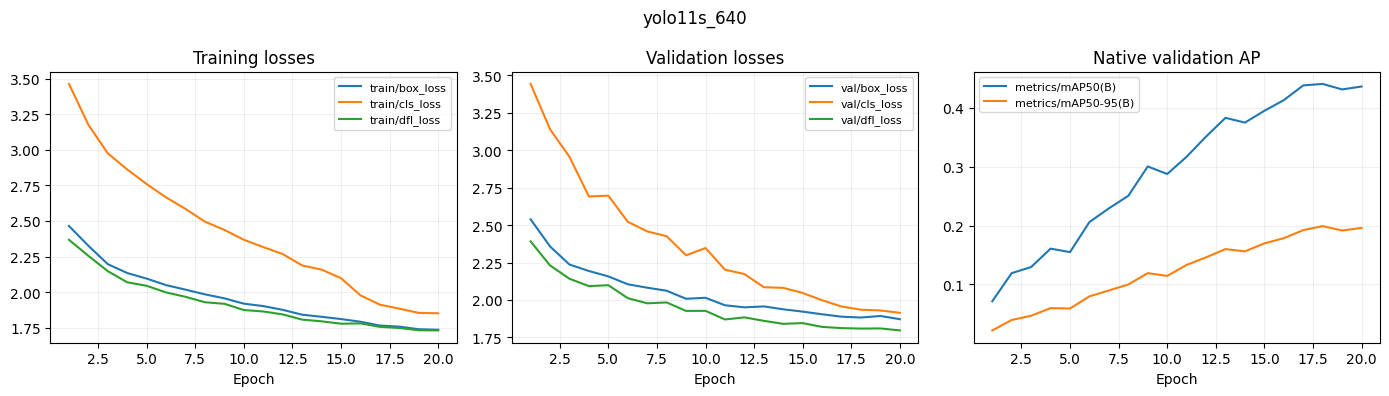

yolo11m_640 : completed 20 stage epochs


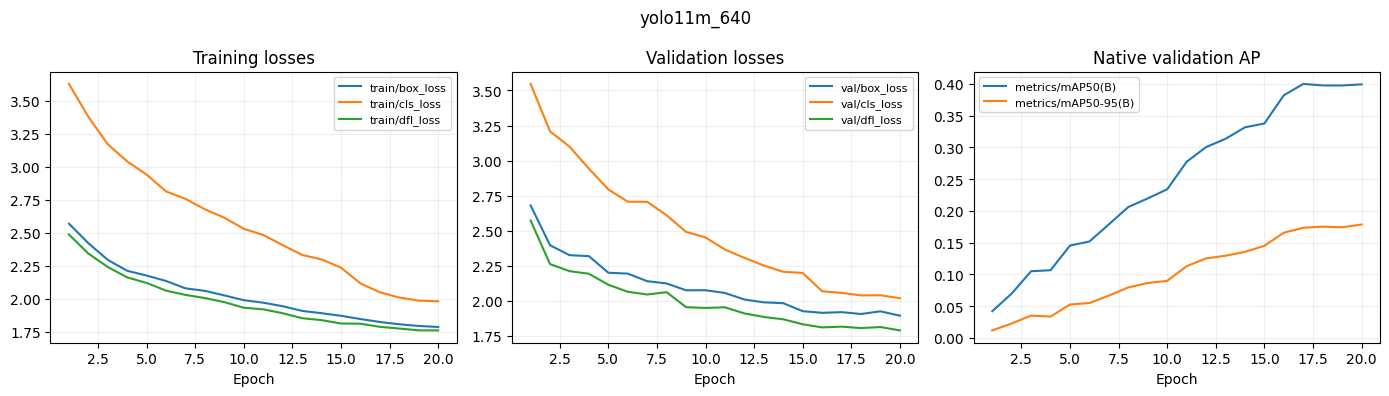

yolov8s_640 : completed 20 stage epochs


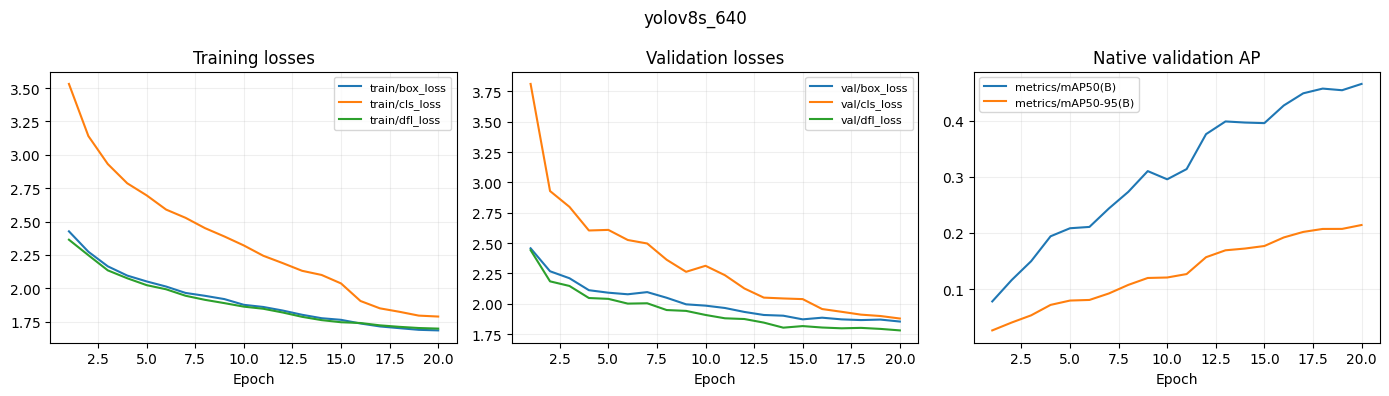

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits/rdd.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mix

/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      2.25G      2.341      3.245       2.29          7        640: 100% ━━━━━━━━━━━━ 1601/1601 6.0it/s 4:260.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 6.5it/s 15.5s.2s
                   all        797       1433      0.141       0.24     0.0996     0.0319
Checkpoint backup ready:


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip

... (36 outputs left out)


20 epochs completed in 1.687 hours.
Optimizer stripped from /kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits/training/yolov8m_640/weights/last.pt, 52.0MB
Optimizer stripped from /kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits/training/yolov8m_640/weights/best.pt, 52.0MB

Validating /kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits/training/yolov8m_640/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,842,076 parameters, 0 gradients, 78.7 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 5.7it/s 17.5s.2s
                   all        797       1433      0.509      0.465      0.436      0.197
    longitudinal_crack        238        357      0.394      0.357      0.296      0.132
      transverse_crack        239        357      0.539      0.524      0.489      0.224


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip

yolov8m_640 : completed 20 stage epochs
Checkpoint backup ready:


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip

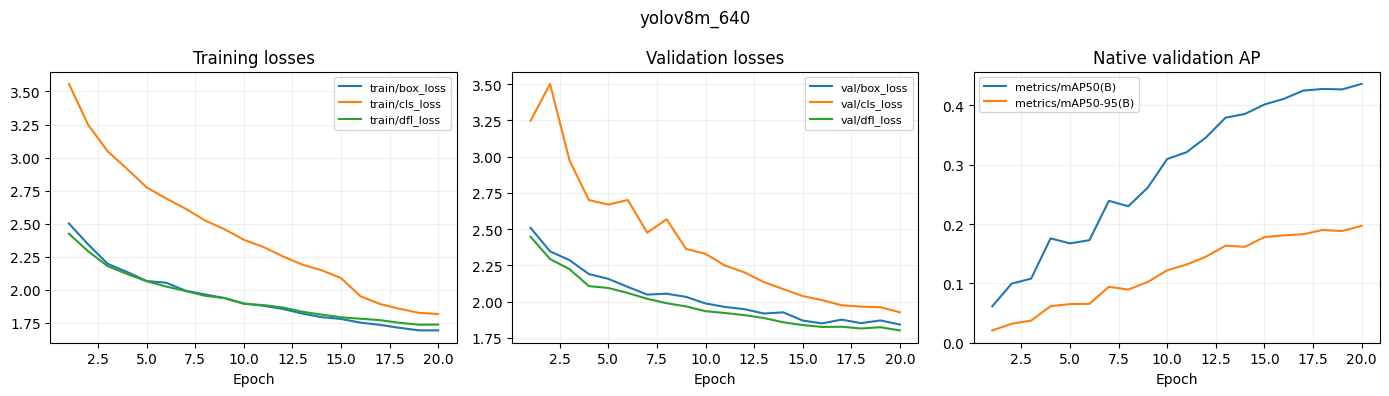

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/RoadScan_YOLO_Benchmarking/benchmark_original_splits/rdd.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mix

/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/20      3.53G      2.168      4.033    0.02424          7        960: 100% ━━━━━━━━━━━━ 1601/1601 4.0it/s 6:410.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 4.7it/s 21.1s.2ss
                   all        797       1433      0.426       0.11     0.0844     0.0285
Checkpoint backup ready:


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/20      3.53G      2.083      3.723    0.02312          9        960: 100% ━━━━━━━━━━━━ 1601/1601 4.0it/s 6:410.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 4.7it/s 21.1s.2ss
                   all        797       1433       0.19      0.169      0.117     0.0376
Checkpoint backup ready:


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip

... (3 outputs left out)

/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       6/20      3.53G      1.969      3.183    0.02108         10        960: 100% ━━━━━━━━━━━━ 1601/1601 4.0it/s 6:390.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 4.8it/s 20.9s.2ss
                   all        797       1433      0.336      0.293      0.235     0.0844
Checkpoint backup ready:


/kaggle/working/RoadScan_YOLO_Benchmarking/RoadScan_Benchmark_Checkpoints.zip


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       7/20      3.53G      1.945      3.087    0.02067          8        960: 59% ━━━━━━━───── 960/1601 4.0it/s 3:59<2:409

In [ ]:
RUNS = {}
for specification in EXPERIMENTS:
    run = train_model(specification)
    RUNS[run['name']] = run
    show_training_history(run)

## Additional Fine Tuning
Continue YOLO26n from its baseline best checkpoint at a lower learning rate. The additional optimization budget is part of this intervention, so a gain cannot be attributed to learning rate alone.

In [ ]:
BASELINE_RUN = RUNS['yolo26n_640']
FINE_SPEC = dict(name='yolo26n_640_finetuned', weights='baseline best checkpoint', imgsz=640)
FINE_RUN = train_model(FINE_SPEC, parent=BASELINE_RUN)
show_training_history(FINE_RUN)
RUNS[FINE_RUN['name']] = FINE_RUN

## Validation Selection
Measure every trained detector and select its confidence threshold without using test results.

In [ ]:
METHODS = {name:method_for(run) for name,run in RUNS.items()}
VALIDATION_ROWS = []
for method in METHODS.values():
    VALIDATION_ROWS.append(validate_method(method))
    pd.DataFrame(VALIDATION_ROWS).to_csv(SESSION/'validation_comparison.csv', index=False)
validation_table = pd.DataFrame(VALIDATION_ROWS)
display(validation_table[['method','mAP50','mAP50_95','macro_F1','threshold']])

## Sliced Inference
Screen tile sizes on validation, then compare the selected tile size against standard inference on all validation images. SAHI includes a full-image pass and class-aware NMS merging.

In [ ]:
# Tile selection uses validation only and reuses the same baseline weights.
screen = random.Random(SEED).sample(ITEMS['val'], min(SAHI_SCREEN_IMAGES,len(ITEMS['val'])))
screen_rows = []
for tile in SAHI_TILES:
    method = method_for(BASELINE_RUN, tile)
    records = collect_predictions(method, 'validation_screen', subset=screen)
    ap = detection_ap(records)
    screen_rows.append(dict(tile=tile,mAP50=float(np.nanmean(ap[:,0])),mAP50_95=float(np.nanmean(ap))))
screen_table = pd.DataFrame(screen_rows).sort_values(['mAP50_95','mAP50'], ascending=False)
screen_table.to_csv(SESSION/'sahi_validation_screen.csv', index=False)
display(screen_table)
tile = int(screen_table.iloc[0]['tile'])
SAHI_METHOD = method_for(BASELINE_RUN, tile)
SAHI_VALIDATION = validate_method(SAHI_METHOD)
METHODS[SAHI_METHOD['method']] = SAHI_METHOD
VALIDATION_ROWS = [r for r in VALIDATION_ROWS if r['method'] != SAHI_METHOD['method']]
VALIDATION_ROWS.append(SAHI_VALIDATION)
pd.DataFrame(VALIDATION_ROWS).to_csv(SESSION/'validation_comparison.csv',index=False)
standard = next(r for r in VALIDATION_ROWS if r['method']=='yolo26n_640')
USE_SAHI = (SAHI_VALIDATION['mAP50_95'] >= standard['mAP50_95']+.005
            and SAHI_VALIDATION['macro_F1'] >= standard['macro_F1'])
SAHI_SELECTED = SAHI_METHOD['method'] if USE_SAHI else 'yolo26n_640'
leaderboard = pd.DataFrame(VALIDATION_ROWS).sort_values(['mAP50_95','mAP50'],ascending=False)
FROZEN_WINNER = str(leaderboard.iloc[0]['method'])
FROZEN_METHODS = []
for name, method in METHODS.items():
    selection = json.loads((SESSION/'evaluation'/name/'frozen_selection.json').read_text())
    FROZEN_METHODS.append(dict(method=name,weights_sha256=method['hash'],threshold=selection['threshold']))
save_json(SESSION/'benchmark_frozen_selection.json',dict(
    dataset_fingerprint=DATASET_FINGERPRINT, selected_on='RDD validation only',
    winner=FROZEN_WINNER, sahi_candidate=SAHI_METHOD['method'],
    sahi_selected=SAHI_SELECTED, methods=FROZEN_METHODS,
))
print('Validation-selected benchmark winner:',FROZEN_WINNER)
print('Validation-selected YOLO26n inference method:',SAHI_SELECTED)

## Frozen Test Evaluation
Evaluate every method on the same RDD and Saudi test images. Keep the validation-selected winner unchanged after viewing test results.

In [ ]:
TEST_ROWS = []
for method in METHODS.values():
    folder = SESSION/'evaluation'/method['method']
    selection = json.loads((folder/'frozen_selection.json').read_text())
    if (selection['weights_sha256'] != method['hash']
        or selection['dataset_fingerprint'] != DATASET_FINGERPRINT
        or selection['protocol_sha256'] != object_hash(inference_protocol(method,DEVICE))):
        raise ValueError('Frozen validation selection no longer matches this model/data/protocol.')
    threshold = float(selection['threshold'])
    for split in ['test','saudi_test']:
        rows = collect_predictions(method, split)
        TEST_ROWS.append(score_rows(method, split, rows, threshold))
        pd.DataFrame(TEST_ROWS).to_csv(SESSION/'test_comparison.csv',index=False)
        visual_evaluation(method, split, rows, threshold)
test_table = pd.DataFrame(TEST_ROWS)
display(test_table[['method','split','mAP50','mAP50_95','macro_precision','macro_recall','macro_F1','image_exact_match']])

## CPU Timing
Measure the same uncached warm CPU pipeline for all methods.

In [ ]:
CPU_ROWS = []
cpu_sample = random.Random(SEED).sample(ITEMS['val'], min(CPU_TIMING_IMAGES,len(ITEMS['val'])))
if not cpu_sample:
    raise ValueError('CPU benchmark requires validation images.')
torch.set_num_threads(CPU_THREADS)
for method in METHODS.values():
    selection = json.loads((SESSION/'evaluation'/method['method']/'frozen_selection.json').read_text())
    threshold = float(selection['threshold'])
    predictor = Predictor(method, device='cpu')
    try:
        for _ in range(3):
            predictor.predict(cpu_sample[0]['image'])
        durations = []
        for record in cpu_sample:
            start = time.perf_counter()
            pred = predictor.predict(record['image'])
            pred = pred[pred[:,4] >= threshold]
            durations.append(1000*(time.perf_counter()-start))
        CPU_ROWS.append(dict(
            method=method['method'], images=len(durations), threads=CPU_THREADS,
            mean_ms=float(np.mean(durations)), median_ms=float(np.median(durations)),
            p95_ms=float(np.percentile(durations,95)),
            scope='Image decode, preprocessing, inference, merging and confidence filtering; excludes weight loading, cache, drawing and UI',
        ))
        pd.DataFrame(CPU_ROWS).to_csv(SESSION/'cpu_latency.csv',index=False)
        print('CPU timing complete:', method['method'])
    finally:
        predictor.close()
cpu_table = pd.DataFrame(CPU_ROWS)
display(cpu_table)

## Comparisons and Figures
Display and save measured comparisons for the report.

In [ ]:
FIGURE_DIR = SESSION/'report_figures'
FIGURE_DIR.mkdir(exist_ok=True)
validation_table = pd.read_csv(SESSION/'validation_comparison.csv')
test_table = pd.read_csv(SESSION/'test_comparison.csv')
cpu_table = pd.read_csv(SESSION/'cpu_latency.csv')

def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/(name+'.png'),dpi=300,bbox_inches='tight')
    fig.savefig(FIGURE_DIR/(name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)

def paired_figure(names, labels, title, filename):
    fig, axes = plt.subplots(1,2,figsize=(13,4.5))
    for ax, split, label in zip(axes,['test','saudi_test'],['RDD test','Saudi test']):
        frame = test_table[(test_table['split']==split)&test_table['method'].isin(names)]
        frame = frame.set_index('method').reindex(names)
        values = frame[['mAP50','mAP50_95','macro_precision','macro_recall','macro_F1']].T*100
        values.columns = labels
        values.plot.bar(ax=ax,rot=0,color=['#64748B','#087F8C'])
        ax.set(title=label,ylabel='Detection score (%)',ylim=(0,105),xlabel='')
        ax.set_xticklabels(['mAP50','mAP50â€“95','Precision','Recall','F1'])
        ax.legend(frameon=False,fontsize=8)
        ax.grid(axis='y',alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle(title)
    finish_figure(fig, filename)

# Architecture and resolution comparisons use the shared validation evaluator.
base_names = [spec['name'] for spec in EXPERIMENTS]
version_table = validation_table[validation_table['method'].isin(base_names)].copy()
version_table = version_table.sort_values(['mAP50_95','mAP50'],ascending=False)
version_table.to_csv(SESSION/'version_comparison.csv',index=False)
display(version_table[['method','input_resolution','mAP50','mAP50_95','macro_F1']])

fig, ax = plt.subplots(figsize=(11,6))
values = version_table['mAP50_95'].to_numpy()*100
bars = ax.barh(version_table['method'],values,color='#087F8C')
ax.bar_label(bars,fmt='%.2f',padding=3)
ax.invert_yaxis()
ax.set(title='YOLO configuration comparison on validation',xlabel='Detection mAP@0.5:0.95 (%)')
ax.set_xlim(0,max(5,float(values.max())*1.2))
finish_figure(fig,'version_validation_comparison')

# Both standard test domains are shown for every trained configuration.
fig, ax = plt.subplots(figsize=(13,5))
table = test_table[test_table['method'].isin(base_names)].pivot(index='method',columns='split',values='mAP50')
table = table.reindex(base_names)[['test','saudi_test']]*100
table.columns=['RDD test','Saudi test']
table.plot.bar(ax=ax,color=['#64748B','#087F8C'],rot=35)
ax.set(title='YOLO detection results on separate test domains',ylabel='Detection mAP@0.5 (%)',xlabel='',ylim=(0,105))
finish_figure(fig,'version_test_comparison')

fine_names=['yolo26n_640','yolo26n_640_finetuned']
fine_table=test_table[test_table['method'].isin(fine_names)].copy()
fine_table.to_csv(SESSION/'finetuning_comparison.csv',index=False)
display(fine_table[['method','split','mAP50','mAP50_95','macro_precision','macro_recall','macro_F1']])
paired_figure(fine_names,['Baseline','Additional fine-tuning'],
              'YOLO26n before and after additional fine-tuning','finetuning_comparison')

sahi_names=['yolo26n_640',SAHI_METHOD['method']]
sahi_table=test_table[test_table['method'].isin(sahi_names)].copy()
sahi_table.to_csv(SESSION/'sahi_comparison.csv',index=False)
display(sahi_table[['method','split','mAP50','mAP50_95','macro_precision','macro_recall','macro_F1']])
paired_figure(sahi_names,['Standard inference','SAHI sliced inference'],
              'YOLO26n standard versus sliced inference','sahi_comparison')

# Per-class AP, confusion matrices and confidence curves remain attached to each method.
selected_methods=list(dict.fromkeys(['yolo26n_640','yolo26n_640_finetuned',SAHI_METHOD['method'],FROZEN_WINNER]))
for name in selected_methods:
    curve=pd.read_csv(SESSION/'evaluation'/name/'validation_F1_vs_confidence.csv')
    fig,ax=plt.subplots(figsize=(8,4))
    for column in ['macro_F1']+[f'F1_{c}' for c in CODES]:
        ax.plot(curve['threshold'],curve[column]*100,label=column)
    threshold=float(json.loads((SESSION/'evaluation'/name/'frozen_selection.json').read_text())['threshold'])
    ax.axvline(threshold,color='black',linestyle='--',label=f'Selected: {threshold:.2f}')
    ax.set(title=f'{name}: validation confidence selection',xlabel='Confidence',ylabel='Detection F1 (%)',ylim=(0,100))
    ax.legend(fontsize=8,frameon=False)
    finish_figure(fig,name+'_validation_F1')
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,split in zip(axes,['test','saudi_test']):
        frame=pd.read_csv(SESSION/'evaluation'/name/f'{split}_per_class.csv')
        bars=ax.bar(frame['code'],frame['AP50']*100,color='#087F8C')
        ax.bar_label(bars,fmt='%.1f',padding=3)
        ax.set(title=split,ylabel='Per-class AP@0.5 (%)',ylim=(0,105))
    fig.suptitle(name)
    finish_figure(fig,name+'_per_class_AP')

fig,ax=plt.subplots(figsize=(12,5))
view=cpu_table.set_index('method').reindex(test_table['method'].drop_duplicates())
view[['mean_ms','p95_ms']].plot.bar(ax=ax,rot=35,color=['#087F8C','#64748B'])
ax.set(title='Warm CPU pipeline latency',ylabel='Time per image (ms)',xlabel='')
finish_figure(fig,'CPU_pipeline_latency')

# Export paired changes without selecting on the test sets.
deltas=[]
for label,names in [('fine_tuning',fine_names),('sahi',sahi_names)]:
    for split in ['test','saudi_test']:
        table=test_table[(test_table['split']==split)&test_table['method'].isin(names)].set_index('method')
        deltas.append(dict(comparison=label,split=split,
            **{metric+'_change_pp':100*(float(table.loc[names[1],metric])-float(table.loc[names[0],metric]))
               for metric in ['mAP50','mAP50_95','macro_precision','macro_recall','macro_F1','image_exact_match']}))
delta_table=pd.DataFrame(deltas)
delta_table.to_csv(SESSION/'paired_changes.csv',index=False)
display(delta_table)

## Results and Backup
Package report figures, tables, settings and checkpoints.

In [ ]:
save_json(SESSION/'benchmark_summary.json',dict(
    dataset_fingerprint=DATASET_FINGERPRINT,
    image_counts={split:len(items) for split,items in ITEMS.items()},
    base_training_configurations=len(EXPERIMENTS),
    validation_selected_winner=FROZEN_WINNER,
    validation_selected_sahi_method=SAHI_SELECTED,
    methods=[dict(method=name,weights_sha256=m['hash'],stage_epochs=m['stage_epochs'],parent=m['parent'])
             for name,m in METHODS.items()],
    limitations=[
        'Fine-tuning includes additional optimization; effects are not attributable to learning rate alone.',
        'One seed and a fixed training budget do not establish statistical significance.',
        'Original partitions and public Saudi test data are preserved; physical scene independence is not certified.',
        'CPU pipeline timing is not live application latency.',
        'The shared COCO benchmark may differ from the native Ultralytics validator.',
        'Full-data scores are not a matched comparison with India-holdout RF-DETR experiments.',
    ],
))

winner=METHODS[FROZEN_WINNER]
deployment=SESSION/'deployment_package'
deployment.mkdir(exist_ok=True)
copy_verified(winner['weights'],deployment/'best.pt')
selection=json.loads((SESSION/'evaluation'/FROZEN_WINNER/'frozen_selection.json').read_text())
save_json(deployment/'selection.json',dict(
    **selection, input_resolution=winner['imgsz'],tile=winner['tile'],
    overlap=SAHI_OVERLAP,full_image_pass=True,nms_iou=NMS_IOU,max_det=MAX_DET,
    class_names=CLASS_NAMES,selection='RDD validation only; test results do not change the winner',
))
report_archive=OUTPUT_BASE/'RoadScan_Benchmark_Report_Results.zip'
backup_archive=OUTPUT_BASE/'RoadScan_Benchmark_Backup.zip'
with zipfile.ZipFile(report_archive,'w',zipfile.ZIP_DEFLATED) as report_zip:
    for path in sorted(SESSION.rglob('*')):
        relative=path.relative_to(SESSION)
        if not path.is_file() or 'prediction_cache' in relative.parts:
            continue
        if path.suffix.lower() in {'.csv','.json','.png','.pdf','.yaml','.txt'}:
            report_zip.write(path,relative)
with zipfile.ZipFile(backup_archive,'w',zipfile.ZIP_STORED) as backup_zip:
    for path in sorted(SESSION.rglob('*')):
        relative=path.relative_to(SESSION)
        if path.is_file() and 'prediction_cache' not in relative.parts and not path.name.endswith(('.copying','.tmp')):
            backup_zip.write(path,Path(SESSION.name)/relative)
print('Report figures and tables:')
display(FileLink(os.path.relpath(report_archive,Path.cwd())))
print('Weights and complete run backup:')
display(FileLink(os.path.relpath(backup_archive,Path.cwd())))
print('Save the backup outside the runtime before ending the session.')

## Interpretation
A single seed does not establish statistical significance. Original partitions are preserved and may contain related road scenes; inspect the similarity audit. Saudi images are public external data, not team-captured local photographs. This benchmark uses the full-data split and must not be treated as a matched comparison with the separate India-holdout experiments.

[Ultralytics training](https://docs.ultralytics.com/modes/train/) · [SAHI inference](https://github.com/obss/sahi/blob/0.11.36/sahi/predict.py)